In [1]:
from pathlib import Path
import sys
import importlib.util
if importlib.util.find_spec('duckdb') is None:
    raise ModuleNotFoundError('duckdb is missing from this Jupyter kernel; run %pip install -r requirements.txt, then restart the kernel.')
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'ypipe').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT))
from ypipe import config,features

SEED=42
np.random.seed(SEED)
MIN_TREND_PERIODS=8  # tối thiểu 8 tuần/tháng để kiểm định xu hướng thăm dò
STL_MIN_DAYS=21  # ít nhất 3 chu kỳ tuần trước khi tách STL chu kỳ 7 ngày
MIN_CHANGE_SEGMENT=4  # mỗi phía điểm đổi cần ít nhất 4 kỳ
MIN_CHANGE_IMPROVEMENT=0.20  # mức giảm SSE tối thiểu 20% để liệt kê điểm đổi ứng viên
N_TOP_SERIES=6
config.DATA.mkdir(parents=True,exist_ok=True)
_previous_con = globals().get('con')
if _previous_con is not None:
    try:
        _previous_con.close()
    except Exception:
        pass
class _NotebookQueryResult:
    def __init__(self, frame):
        self._frame = frame
    def df(self):
        return self._frame.copy()
    def fetchdf(self):
        return self._frame.copy()
    def fetchone(self):
        if self._frame.empty:
            return None
        return tuple(self._frame.iloc[0].tolist())
    def fetchall(self):
        return list(self._frame.itertuples(index=False, name=None))

class _NotebookReadOnlyDB:
    """Run each read query on a short-lived connection to avoid retaining a file lock."""
    def __init__(self, path):
        self.path = Path(path)
    def execute(self, sql, parameters=None):
        if not self.path.exists():
            if sql.strip().lower() == 'show tables':
                return _NotebookQueryResult(pd.DataFrame({'name': pd.Series(dtype='object')}))
            return _NotebookQueryResult(pd.DataFrame())
        db = duckdb.connect(str(self.path), read_only=True)
        try:
            result = db.execute(sql) if parameters is None else db.execute(sql, parameters)
            frame = result.fetchdf()
        finally:
            db.close()
        return _NotebookQueryResult(frame)
    def close(self):
        # Queries already close their own connection before returning.
        return None

con=_NotebookReadOnlyDB(config.DB_PATH)
TABLES=set(con.execute('SHOW TABLES').fetchdf()['name'])
print(f'Database: {config.DB_PATH} | seed={SEED}')

Database: D:\project\bigdata\data\warehouse.duckdb | seed=42


# Xu hướng theo thời gian — Stage 5

## Câu hỏi
Cơ cấu thể loại/chủ đề, tỷ lệ Shorts, độ dài, xem ban đêm và cường độ phiên thay đổi ra sao theo tuần/tháng?

## Phương pháp
Tạo chuỗi tuần và tháng theo `config.TZ`. Mỗi kỳ có tỷ trọng category/topic, tỷ lệ Shorts, độ dài trung bình, tỷ lệ lượt mở ban đêm và số phiên/ngày/người dùng hoạt động. Xu hướng kiểm tra bằng Kendall tau; STL dùng chu kỳ tuần trên chuỗi ngày nếu đủ độ dài; điểm đổi chỉ là ứng viên dựa trên mức giảm SSE. Các chỉ số tần suất được chuẩn hóa theo người dùng hoạt động trong kỳ.

In [2]:
raw=con.execute('SELECT * FROM watch_raw').df() if 'watch_raw' in TABLES else pd.DataFrame()
meta=con.execute('SELECT * FROM video_metadata').df() if 'video_metadata' in TABLES else pd.DataFrame()
video_topics=con.execute('SELECT video_id,topic_id FROM video_topics').df() if 'video_topics' in TABLES else pd.DataFrame(columns=['video_id','topic_id'])
topic_labels=con.execute('SELECT topic_id,label FROM topics').df() if 'topics' in TABLES else pd.DataFrame(columns=['topic_id','label'])
if len(raw) and len(meta):
    events=features.build_events(raw,meta)
    if len(video_topics): events=events.merge(video_topics,on='video_id',how='left')
    else: events['topic_id']=pd.NA
    if len(topic_labels): events=events.merge(topic_labels,on='topic_id',how='left')
    else: events['label']=pd.NA
    events['topic_label']=events['label'].fillna('Chưa gán chủ đề')
else:
    events=pd.DataFrame(columns=['ts','user_id','session_id','category_name','duration_sec','is_night','video_id','topic_label'])

def build_period_series(data,freq):
    if data.empty: return {},pd.DataFrame()
    frame=data.copy()
    period=frame['ts'].dt.to_period(freq)
    frame['period']=period.astype(str)
    frame['period_start']=period.dt.start_time
    frame['period_days']=period.map(lambda p:(p.end_time.normalize()-p.start_time.normalize()).days+1).astype(int)
    summary=frame.groupby(['period','period_start','period_days']).agg(
        n_events=('video_id','size'),active_users=('user_id','nunique'),n_sessions=('session_id','nunique'),
        night_ratio=('is_night','mean'),avg_duration_sec=('duration_sec','mean')).reset_index()
    duration=frame.dropna(subset=['duration_sec']).groupby('period').agg(
        shorts_ratio=('duration_sec',lambda s:float((s<=config.SHORTS_MAX_SEC).mean())),
        avg_duration_sec_known=('duration_sec','mean')).reset_index()
    summary=summary.merge(duration,on='period',how='left')
    summary['avg_duration_min']=summary.pop('avg_duration_sec_known').div(60)
    summary['sessions_per_active_user_day']=summary['n_sessions']/(summary['active_users'].clip(lower=1)*summary['period_days'])
    summary['events_per_active_user_day']=summary['n_events']/(summary['active_users'].clip(lower=1)*summary['period_days'])
    categories=(frame.dropna(subset=['category_name']).groupby(['period','category_name']).size()
        .rename('n').reset_index())
    if len(categories): categories['share']=categories['n']/categories.groupby('period')['n'].transform('sum')
    topics=frame.groupby(['period','topic_label']).size().rename('n').reset_index()
    if len(topics): topics['share']=topics['n']/topics.groupby('period')['n'].transform('sum')
    return {'categories':categories,'topics':topics},summary.sort_values('period_start').reset_index(drop=True)

weekly_parts,weekly=build_period_series(events,'W-SUN')
monthly_parts,monthly=build_period_series(events,'M')
print(f'Events: {len(events):,} | tuần: {len(weekly):,} | tháng: {len(monthly):,}')
display(weekly.tail(12))

Events: 156,838 | tuần: 437 | tháng: 102


,period,period_start,period_days,n_events,active_users,n_sessions,night_ratio,avg_duration_sec,shorts_ratio,avg_duration_min,sessions_per_active_user_day,events_per_active_user_day
425,2026-07-27/2026-08-02,2026-07-27,7,2183,11,237,0.325240,907.940000,0.375238,15.132333,3.077922,28.350649
426,2026-08-03/2026-08-09,2026-08-03,7,2581,12,214,0.266951,890.100366,0.360829,14.835006,2.547619,30.726190
427,2026-08-10/2026-08-16,2026-08-10,7,2808,11,230,0.184117,1030.238043,0.420530,17.170634,2.987013,36.467532
428,2026-08-17/2026-08-23,2026-08-17,7,3099,12,269,0.221362,1101.922792,0.500000,18.365380,3.202381,36.892857
429,2026-08-24/2026-08-30,2026-08-24,7,3230,13,264,0.313622,966.825536,0.524691,16.113759,2.901099,35.494505
430,2026-08-31/2026-09-06,2026-08-31,7,3386,11,210,0.165092,841.264215,0.536774,14.021070,2.727273,43.974026
431,2026-09-07/2026-09-13,2026-09-07,7,3142,14,247,0.237428,758.509452,0.498370,12.641824,2.520408,32.061224
432,2026-09-14/2026-09-20,2026-09-14,7,2868,12,204,0.261158,735.143777,0.440629,12.252396,2.428571,34.142857
433,2026-09-21/2026-09-27,2026-09-21,7,2776,12,230,0.269452,1200.802801,0.488758,20.013380,2.738095,33.047619
434,2026-09-28/2026-10-04,2026-09-28,7,2676,14,216,0.318012,933.839758,0.481104,15.563996,2.204082,27.306122


## Kết quả: tỷ trọng category/topic và hoạt động
Chuỗi tỷ trọng dùng lượt mở có metadata tương ứng làm mẫu số. Các tỷ lệ hoạt động được chia cho số người dùng có hoạt động trong kỳ và số ngày kỳ lịch.

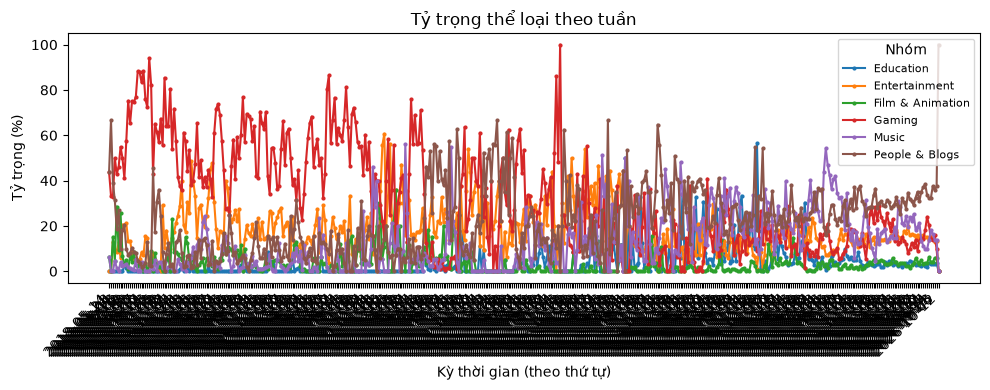

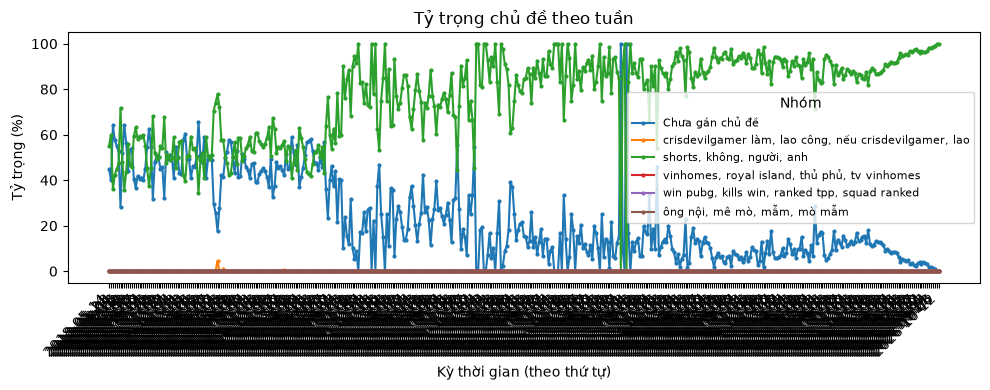

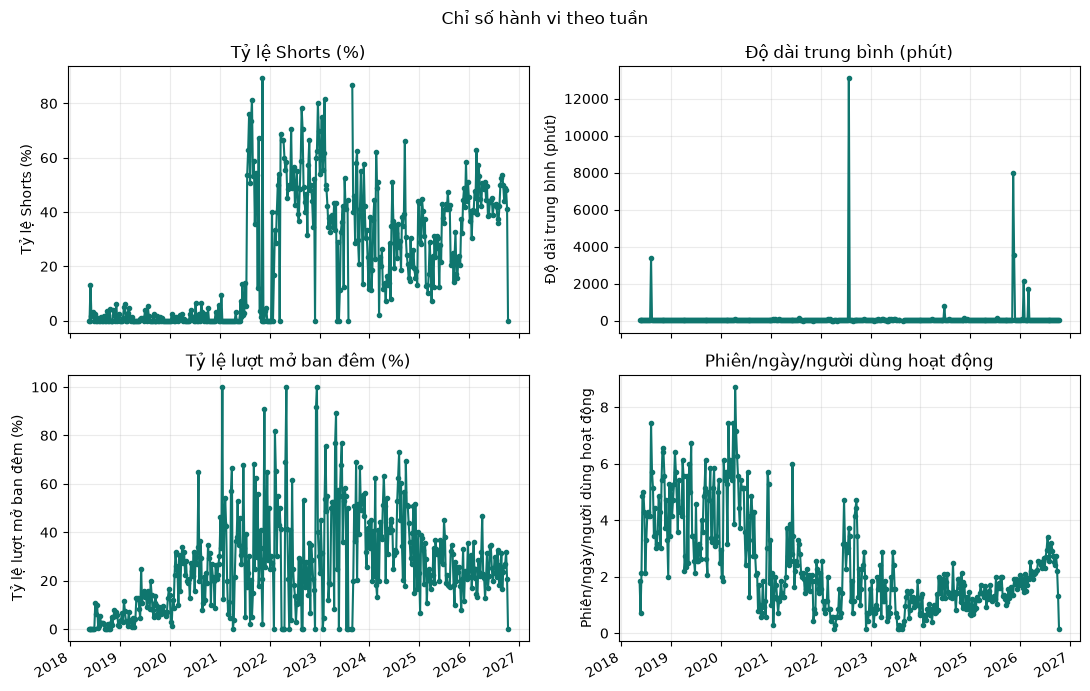

,Chỉ số,Số tuần,Kendall tau,p-value
0,shorts_ratio,435,0.422675,1.020715e-37
1,avg_duration_min,435,0.168727,1.460516e-07
2,night_ratio,437,0.285009,6.621548e-19
3,sessions_per_active_user_day,437,-0.312981,2.418692e-22


In [3]:
def plot_shares(parts,key,title,ylabel):
    data=parts.get(key,pd.DataFrame())
    if data.empty: print(f'Chưa có chuỗi {title.lower()} để vẽ.'); return
    item_column='category_name' if key=='categories' else 'topic_label'
    top=data.groupby(item_column)['n'].sum().sort_values(ascending=False).head(N_TOP_SERIES).index
    data=data[data[item_column].isin(top)]
    pivot=data.pivot(index='period',columns=item_column,values='share').fillna(0)
    pivot.index=pd.to_datetime(pivot.index.str.split('/').str[0],errors='coerce') if '/' in str(pivot.index[0]) else pivot.index
    fig,ax=plt.subplots(figsize=(10,4))
    for col in pivot: ax.plot(range(len(pivot)),pivot[col]*100,marker='o',markersize=2,label=str(col))
    ax.set_title(title); ax.set_xlabel('Kỳ thời gian (theo thứ tự)'); ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(pivot))); ax.set_xticklabels([str(x)[:10] for x in pivot.index],rotation=45,ha='right')
    ax.legend(title='Nhóm',fontsize=8); plt.tight_layout(); plt.show()

plot_shares(weekly_parts,'categories','Tỷ trọng thể loại theo tuần','Tỷ trọng (%)')
plot_shares(weekly_parts,'topics','Tỷ trọng chủ đề theo tuần','Tỷ trọng (%)')
if len(weekly):
    fig,axes=plt.subplots(2,2,figsize=(11,7),sharex=True)
    metrics=[('shorts_ratio','Tỷ lệ Shorts (%)',100),('avg_duration_min','Độ dài trung bình (phút)',1),
             ('night_ratio','Tỷ lệ lượt mở ban đêm (%)',100),('sessions_per_active_user_day','Phiên/ngày/người dùng hoạt động',1)]
    for ax,(column,label,multiplier) in zip(axes.flat,metrics):
        ax.plot(weekly.period_start,weekly[column]*multiplier,marker='o',markersize=3,color='#0f766e')
        ax.set_title(label); ax.set_ylabel(label); ax.grid(True,alpha=.25)
    fig.suptitle('Chỉ số hành vi theo tuần'); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

trend_rows=[]
for metric in ['shorts_ratio','avg_duration_min','night_ratio','sessions_per_active_user_day']:
    valid=weekly[metric].dropna() if len(weekly) else pd.Series(dtype=float)
    if len(valid)>=MIN_TREND_PERIODS:
        tau,p=kendalltau(np.arange(len(valid)),valid.to_numpy())
        trend_rows.append({'Chỉ số':metric,'Số tuần':len(valid),'Kendall tau':tau,'p-value':p})
trend_table=pd.DataFrame(trend_rows)
if len(trend_table): display(trend_table)
else: print(f'Cần tối thiểu {MIN_TREND_PERIODS} tuần hợp lệ để kiểm định Kendall.')

## Kết quả: chu kỳ tuần và điểm đổi ứng viên
STL tách xu hướng, mùa vụ 7 ngày và phần dư trên số lượt mở/ngày. Thuật toán điểm đổi dưới đây chỉ tìm một điểm cắt làm giảm SSE; nó gợi ý vị trí cần xem lại, không phải kiểm định hay phát hiện chắc chắn.

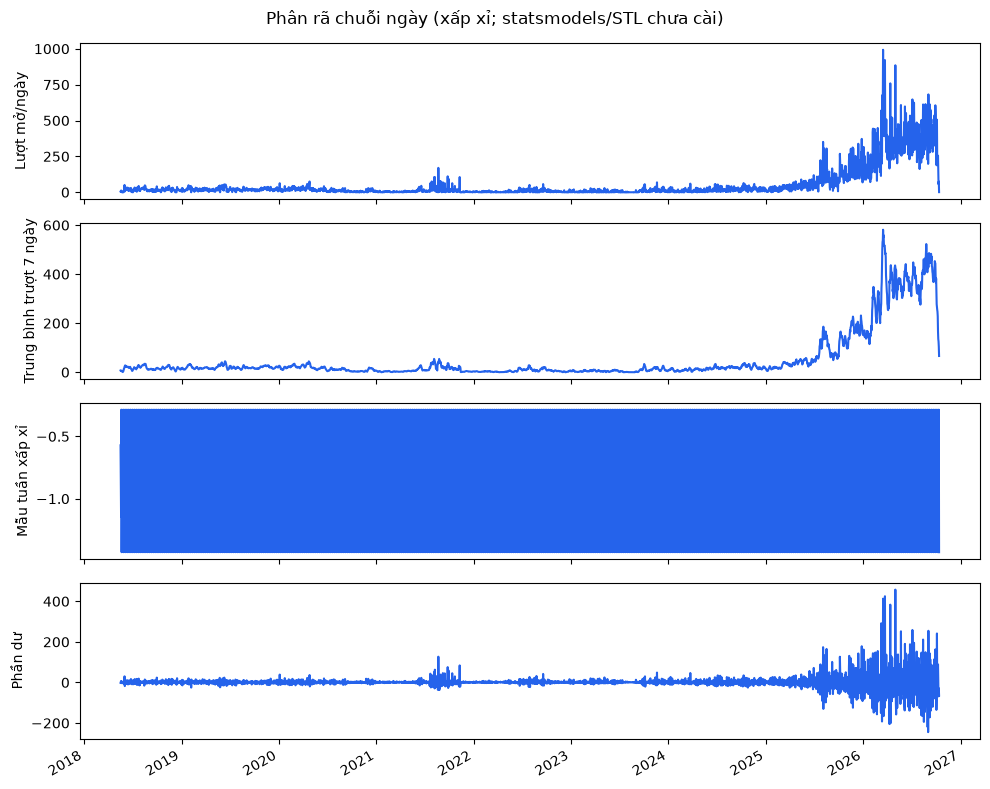

Đã dùng phân rã xấp xỉ theo trung bình trượt và trung vị thứ trong tuần; đây không phải STL.


,Chỉ số,Kỳ ứng viên,Mức giảm SSE
0,shorts_ratio,2021-07-19,0.567965
2,sessions_per_active_user_day,2020-09-07,0.539294
1,night_ratio,2020-02-03,0.259612


In [4]:
daily=pd.DataFrame()
if len(events):
    daily=(events.groupby(events['ts'].dt.floor('D')).agg(n_events=('video_id','size'),
        active_users=('user_id','nunique'),n_sessions=('session_id','nunique')).rename_axis('date').reset_index())
    daily['sessions_per_active_user']=daily.n_sessions/daily.active_users.clip(lower=1)

stl_result=None
try:
    from statsmodels.tsa.seasonal import STL
    if len(daily)>=STL_MIN_DAYS:
        daily_series=daily.set_index('date')['n_events'].asfreq('D',fill_value=0)
        stl_result=STL(daily_series,period=7,robust=True).fit()
        fig,axes=plt.subplots(4,1,figsize=(10,8),sharex=True)
        for ax,series,label in zip(axes,[daily_series,stl_result.trend,stl_result.seasonal,stl_result.resid],
            ['Lượt mở/ngày','Xu hướng','Chu kỳ tuần','Phần dư']):
            ax.plot(series.index,series.values,color='#2563eb'); ax.set_ylabel(label)
        fig.suptitle('STL chu kỳ 7 ngày'); fig.autofmt_xdate(); plt.tight_layout(); plt.show()
    else: print(f'Cần ít nhất {STL_MIN_DAYS} ngày để tách STL chu kỳ tuần; hiện có {len(daily)} ngày.')
except ImportError:
    if len(daily)>=STL_MIN_DAYS:
        daily_series=daily.set_index('date')['n_events'].asfreq('D',fill_value=0)
        trend=daily_series.rolling(7,center=True,min_periods=1).mean()
        detrended=daily_series-trend
        weekly_profile=detrended.groupby(detrended.index.dayofweek).median()
        seasonal=pd.Series([weekly_profile.get(day,0.0) for day in daily_series.index.dayofweek],index=daily_series.index)
        residual=daily_series-trend-seasonal
        fig,axes=plt.subplots(4,1,figsize=(10,8),sharex=True)
        for ax,series,label in zip(axes,[daily_series,trend,seasonal,residual],
            ['Lượt mở/ngày','Trung bình trượt 7 ngày','Mẫu tuần xấp xỉ','Phần dư']):
            ax.plot(series.index,series.values,color='#2563eb'); ax.set_ylabel(label)
        fig.suptitle('Phân rã chuỗi ngày (xấp xỉ; statsmodels/STL chưa cài)'); fig.autofmt_xdate(); plt.tight_layout(); plt.show()
        print('Đã dùng phân rã xấp xỉ theo trung bình trượt và trung vị thứ trong tuần; đây không phải STL.')
    else: print('statsmodels chưa cài và chuỗi chưa đủ ngày cho phân rã xấp xỉ.')

def one_change_candidate(series):
    values=pd.Series(series).dropna().to_numpy(dtype=float); n=len(values)
    if n<2*MIN_CHANGE_SEGMENT: return None
    baseline=((values-values.mean())**2).sum()
    if baseline<=0: return None
    candidates=[]
    for split in range(MIN_CHANGE_SEGMENT,n-MIN_CHANGE_SEGMENT+1):
        left,right=values[:split],values[split:]
        error=((left-left.mean())**2).sum()+((right-right.mean())**2).sum()
        candidates.append((1-error/baseline,split))
    improvement,split=max(candidates)
    return (improvement,split) if improvement>=MIN_CHANGE_IMPROVEMENT else None

change_rows=[]
if len(weekly):
    for metric in ['shorts_ratio','avg_duration_min','night_ratio','sessions_per_active_user_day']:
        candidate=one_change_candidate(weekly[metric])
        if candidate:
            improvement,split=candidate
            change_rows.append({'Chỉ số':metric,'Kỳ ứng viên':weekly.iloc[split]['period_start'],
                               'Mức giảm SSE':improvement})
change_table=pd.DataFrame(change_rows).sort_values('Mức giảm SSE',ascending=False) if change_rows else pd.DataFrame()
if len(change_table): display(change_table)
else: print('Chưa có điểm đổi ứng viên vượt ngưỡng cải thiện SSE.')
con.close()

## Insight
Chỉ mô tả xu hướng quan sát được trong giai đoạn hiện có. Các tỷ lệ theo kỳ đã được chuẩn hóa theo người dùng hoạt động; nên đối chiếu số người dùng cùng từng kỳ để xem thay đổi cơ cấu mẫu.

## Hạn chế
Dữ liệu dự kiến chỉ phủ khoảng 5–9 tháng nên không thể kết luận mùa vụ theo năm. Tuần/tháng cuối có thể chưa đầy đủ. Kendall tau không loại bỏ yếu tố gây nhiễu; nhiều chuỗi và nhiều kiểm định làm tăng khả năng thấy xu hướng ngẫu nhiên. STL cần chuỗi ngày đủ dài; điểm đổi SSE chỉ là ứng viên. Tỷ lệ category/topic chỉ tính sự kiện có metadata/nhãn tương ứng. Không suy ra quan hệ nhân quả.